# Ballot-level anomalies — Bulgarian parliamentary election (19 Apr 2026)

The Benford notebook looked for **invented numbers** and the turnout notebook for **stuffed ballot boxes**. This one targets
manipulation that happens **during the count or at the voters' list**, which changes neither digits nor turnout. Same methods as
the presidential notebooks, plus one test that only the parliamentary data allow: the machines' own electronic records.

| # | Question | Method |
|---|---|---|
| 1 | Do **paper-ballot** stations give different results than **machine** stations? | **Regression discontinuity** at the legal 300-voter threshold |
| 2 | Are there stations with suspiciously many **invalid ballots**, and does a high invalid rate favour anyone? | Beta-binomial outlier test vs. the municipality, plus a within-municipality regression |
| 3 | How do **voters added on election day** (“под чертата”) vote, and where are there unusually many? | Fixed-effects regression, plus outlier test |
| 4 | Do the **protocols add up**? | Arithmetic consistency checks |
| 5 | Does the **hand count of machine receipts** match the **machine's electronic count**? | Station-by-station comparison with the signed `suemg` machine records |
| 6 | Which stations raise **several red flags at once**? | Combined watch-list |
| 7 | **How many votes would it take** to change the majority? | Seat allocation (Hare–Niemeyer) with perturbed vote totals |

A note on wording: every test here finds **statistical anomalies**. An anomaly is a reason to look at the scanned protocol or
observer reports, not proof of fraud.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from load_data import load_votes, load_sections, load_protocol_totals, load_machine_counts, PARLIAMENT, ROUND1

votes = load_votes(election=PARLIAMENT)
meta = load_sections(PARLIAMENT)
pt = load_protocol_totals(PARLIAMENT)            # one protocol per station; forms 24/28 paper, 26/30 paper + machine
NONE = "Не подкрепям никого"
cand_cols = [c for c in votes.columns if c != NONE]
ranked = list(votes[cand_cols].sum().sort_values(ascending=False).index)
TOP = ranked[:4]
NEAR = [c for c in ranked if c[3:] in ("МЕЧ", "Величие")]     # just below the 4% threshold: their votes decide the majority (§7)
OUTCOMES = TOP + NEAR + [NONE]
WIN = ranked[0]
short = lambda c: c.split(" ", 1)[1] if c[:2].isdigit() else c

df = meta.join(votes)
df["form"] = pt["form"].reindex(df.index)
df["registered"] = df["voters_list"] + df["voters_added"]
df["voted"] = df["voted_signatures"]
df["turnout"] = df["voted"] / df["registered"]
df["valid"] = votes.sum(axis=1)
df["invalid"] = pt["invalid_paper"].reindex(df.index).fillna(0).astype(int)   # machines cannot produce invalid votes
df["paper"] = df["machines"] == 0
for c in votes.columns:
    df[f"share|{c}"] = df[c] / df["valid"]
dom = df[~df["abroad"] & (df["mobile"] == 0) & (df["ship"] == 0) & (df["valid"] > 0)].copy()
print(f"{len(dom):,} domestic regular stations: {dom['paper'].sum():,} paper-only, {(~dom['paper']).sum():,} with machines")

11,901 domestic regular stations: 2,547 paper-only, 9,354 with machines


In [2]:
# ---- chart style ----
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#c3c2b7", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110,
    "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
def suptitle(fig, s): fig.suptitle(s, x=0.01, ha="left", fontsize=13, fontweight="bold")

# ---- small stats toolkit (numpy only) ----
def wls_cluster(y, X, w, groups):
    # Weighted least squares with cluster-robust (CR1) standard errors.
    y, X, w = np.asarray(y, float), np.asarray(X, float), np.asarray(w, float)
    sw = np.sqrt(w); Xw, yw = X * sw[:, None], y * sw
    XtX_inv = np.linalg.pinv(Xw.T @ Xw)
    beta = XtX_inv @ Xw.T @ yw
    u = yw - Xw @ beta
    g = pd.factorize(np.asarray(groups))[0]; G = g.max() + 1
    S = np.zeros((G, X.shape[1])); np.add.at(S, g, Xw * u[:, None])
    n, k = X.shape
    V = XtX_inv @ (S.T @ S) @ XtX_inv * (G / (G - 1)) * ((n - 1) / max(n - k, 1))
    return beta, np.sqrt(np.diag(V))

def demean(a, groups, w):
    # Subtract the weighted group mean = fixed effects for each group.
    a = pd.DataFrame(np.asarray(a, float)); g = pd.Series(np.asarray(groups)); w = pd.Series(np.asarray(w, float))
    m = a.mul(w, axis=0).groupby(g).transform("sum").div(w.groupby(g).transform("sum"), axis=0)
    return (a - m).to_numpy()

def betabinom_outliers(x, n, p_expected, q=0.01):
    # One-sided test for 'too many' events given an expected rate, allowing for over-dispersion (beta-binomial).
    # Returns (q-values, fitted intra-class correlation rho).
    # rho (extra between-station variation) is fitted by maximum likelihood.
    from scipy.optimize import minimize_scalar
    x, n, p = np.asarray(x, float), np.asarray(n, float), np.clip(np.asarray(p_expected, float), 1e-4, 0.999)
    xi, ni = x.astype(int), n.astype(int)
    nll = lambda r: -stats.betabinom.logpmf(xi, ni, p * (1 - r) / r, (1 - p) * (1 - r) / r).sum()
    rho = float(minimize_scalar(nll, bounds=(1e-5, 0.3), method="bounded").x)
    a, b = p * (1 - rho) / rho, (1 - p) * (1 - rho) / rho
    pv = np.where(x > 0, stats.betabinom.sf(x - 1, n.astype(int), a, b), 1.0)
    return stats.false_discovery_control(np.clip(pv, 0, 1)), rho

def loo_rate(events, trials, groups, fallback):
    # Rate in the rest of the municipality (leave-one-out), so a station isn't compared with itself.
    g = pd.Series(np.asarray(groups))
    e, t = pd.Series(np.asarray(events, float)), pd.Series(np.asarray(trials, float))
    r = (e.groupby(g).transform("sum") - e) / (t.groupby(g).transform("sum") - t)
    return r.where(np.isfinite(r), fallback).fillna(fallback).to_numpy()

## 1. Paper vs machine: a natural experiment at 300 voters
Stations with **300 or more** voters on the list get a voting machine; smaller ones vote on paper only. Stations with 290 and
310 voters come from the same kinds of neighbourhoods, and **mainly the voting method differs**. If paper counts were systematically
manipulated in someone's favour, that party's share would **jump** at the 300 line. This is a *regression discontinuity design*
(RDD): fit a line on each side and measure the gap at 300.

The rule is not followed perfectly in this election (table below): a few dozen stations of 300–400 voters had no machine, and a few
small ones had one. The RDD therefore measures the effect of *crossing the threshold* (an "intention-to-treat" estimate), which is
slightly diluted.

In [3]:
lo_hi = dom.groupby(pd.cut(dom["voters_list"], [0, 200, 280, 300, 320, 400, 10**6], right=False), observed=True)["paper"].agg(["size", "mean"])
lo_hi.columns = ["stations", "share using paper"]
mst = dom[~dom["paper"]]
pshare = mst.groupby(pd.cut(mst["voters_list"], [0, 200, 280, 300, 320, 400, 10**6], right=False), observed=True).apply(
    lambda t: pt.loc[t.index, "paper_in_box"].sum() / (pt.loc[t.index, "paper_in_box"] + pt.loc[t.index, "machine_in_box"]).sum(), include_groups=False)
lo_hi["paper ballots as % of votes in machine stations"] = pshare
lo_hi.style.format({"share using paper": "{:.1%}", "paper ballots as % of votes in machine stations": "{:.0%}"})

,stations,share using paper,paper ballots as % of votes in machine stations
voters_list,,,
"[0, 200)",1918,99.6%,69%
"[200, 280)",459,96.9%,63%
"[280, 300)",114,89.5%,82%
"[300, 320)",128,43.0%,76%
"[320, 400)",568,5.5%,63%
"[400, 1000000)",8714,0.0%,48%


**Validity check: is there bunching at the threshold?** If officials split stations to keep them just under 300 (to avoid
machines), there would be too many stations at 280–299 and too few at 300–319.

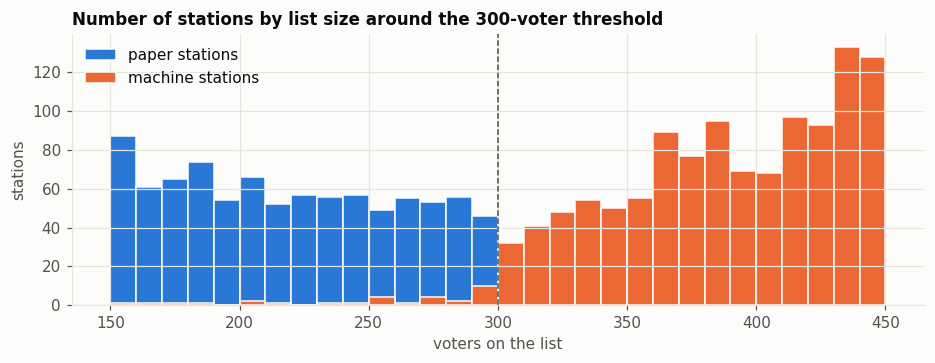

stations with 280–299 voters: 114;  300–319: 128  (binomial test for a difference: p = 0.40)


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
w = dom[(dom["voters_list"] >= 150) & (dom["voters_list"] < 450)]
bins = np.arange(150, 451, 10)
ax.hist(w.loc[w["paper"], "voters_list"], bins=bins, color=BLUE, edgecolor=SURFACE, label="paper stations")
ax.hist(w.loc[~w["paper"], "voters_list"], bins=bins, color=ORANGE, edgecolor=SURFACE, label="machine stations")
ax.axvline(300, color=INK2, lw=1, ls="--")
ax.set_xlabel("voters on the list"); ax.set_ylabel("stations"); ax.legend()
ax.set_title("Number of stations by list size around the 300-voter threshold")
plt.show()
below, above = ((w["voters_list"] >= 280) & (w["voters_list"] < 300)).sum(), ((w["voters_list"] >= 300) & (w["voters_list"] < 320)).sum()
print(f"stations with 280–299 voters: {below};  300–319: {above}  "
      f"(binomial test for a difference: p = {stats.binomtest(below, below + above).pvalue:.2f})")

In [5]:
def rd_estimate(data, y_col, bw, fe=False):
    s = data[(data["voters_list"] >= 300 - bw) & (data["voters_list"] < 300 + bw)]
    x = (s["voters_list"] - 300).to_numpy(float); M = (x >= 0).astype(float)
    y = s[y_col].to_numpy(float); wts = s["valid"].to_numpy(float)
    if fe:   # compare stations within the same municipality
        X = demean(np.column_stack([M, x, M * x]), s["municipality"], wts)
        y = demean(y, s["municipality"], wts)[:, 0]
        b, se = wls_cluster(y, X, wts, s["municipality"]); return b[0], se[0], len(s)
    X = np.column_stack([np.ones(len(s)), M, x, M * x])
    b, se = wls_cluster(y, X, wts, s["municipality"]); return b[1], se[1], len(s)

dom["invalid share"] = dom["invalid"] / (dom["invalid"] + dom["valid"])
rd_outcomes = {short(c): f"share|{c}" for c in OUTCOMES} | {"turnout": "turnout", "invalid ballots (positive control)": "invalid share"}
rows = {}
for name, col in rd_outcomes.items():
    for bw in [50, 100]:
        for fe in [False, True]:
            b, se, n = rd_estimate(dom, col, bw, fe)
            rows.setdefault(name, {})[f"±{bw} voters{' + municipality FE' if fe else ''}"] = f"{b*100:+.1f} ± {1.96*se*100:.1f}"
rd_tab = pd.DataFrame(rows).T
print("Jump at 300 voters (machine side minus paper side), percentage points, ± 95% CI")
rd_tab

Jump at 300 voters (machine side minus paper side), percentage points, ± 95% CI


,±50 voters,±50 voters + municipality FE,±100 voters,±100 voters + municipality FE
Прогресивна България,-0.6 ± 5.3,-2.3 ± 4.4,+0.1 ± 4.1,-1.1 ± 3.2
ГЕРБ–СДС,+1.7 ± 4.9,-1.6 ± 3.4,-0.1 ± 3.2,-1.4 ± 2.0
ПП–ДБ,-1.8 ± 1.6,-1.0 ± 1.6,-1.3 ± 1.3,-0.3 ± 1.0
ДПС,+1.6 ± 7.1,+4.0 ± 4.7,+1.3 ± 5.8,+2.1 ± 3.2
МЕЧ,+0.3 ± 0.7,+0.2 ± 0.7,+0.2 ± 0.6,+0.1 ± 0.5
Величие,+0.5 ± 0.9,+0.3 ± 0.8,+0.6 ± 0.6,+0.4 ± 0.5
Не подкрепям никого,-0.1 ± 0.4,+0.0 ± 0.5,-0.2 ± 0.3,-0.1 ± 0.3
turnout,+2.7 ± 3.9,+1.8 ± 4.2,+1.2 ± 3.3,+0.3 ± 3.3
invalid ballots (positive control),+0.2 ± 0.6,+0.4 ± 0.7,-0.2 ± 0.5,-0.0 ± 0.5


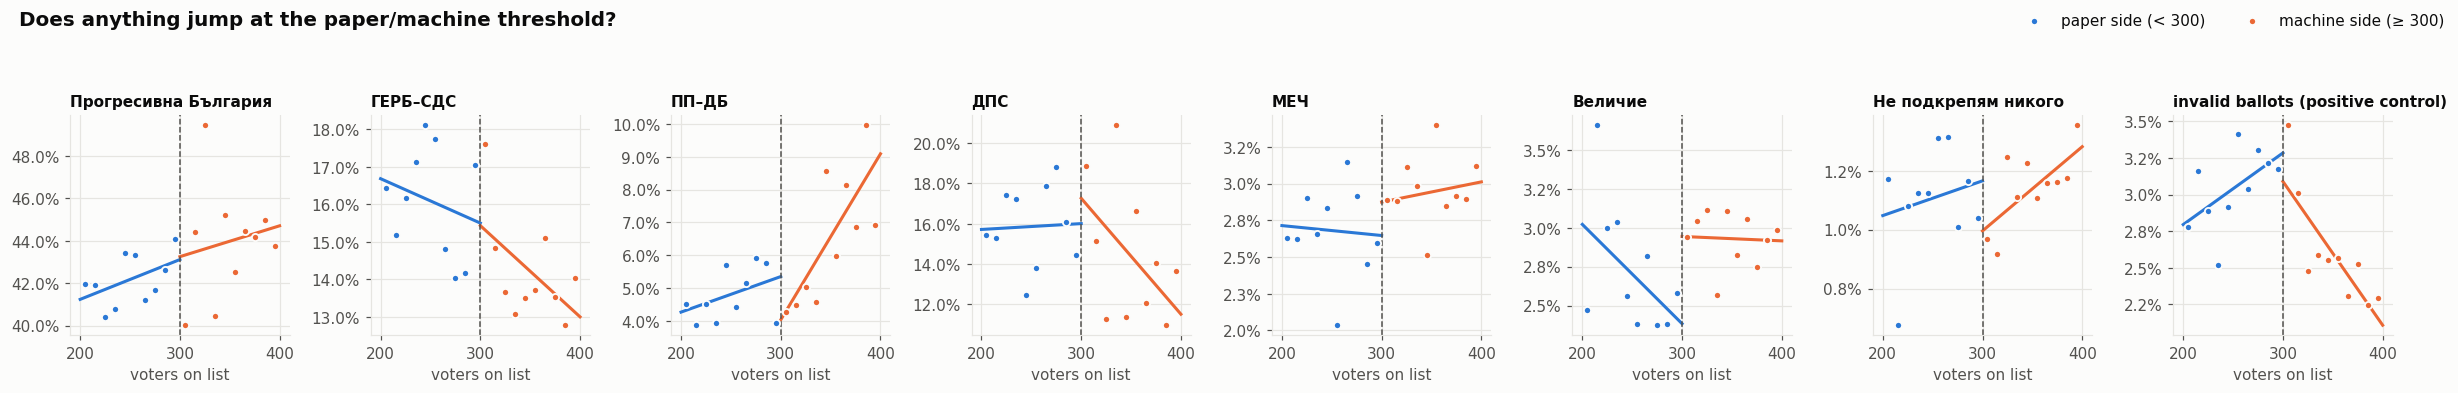

In [6]:
fig, axes = plt.subplots(1, 8, figsize=(22, 3.6))
BW = 100
s = dom[(dom["voters_list"] >= 300 - BW) & (dom["voters_list"] < 300 + BW)].copy()
s["bin"] = (s["voters_list"] // 10) * 10 + 5
for ax, (name, col) in zip(axes, list(rd_outcomes.items())[:7] + [list(rd_outcomes.items())[-1]]):
    g = s.groupby("bin").apply(lambda t: np.average(t[col], weights=t["valid"]), include_groups=False)
    side = g.index >= 300
    ax.scatter(g.index[~side], g[~side], s=22, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3, label="paper side (< 300)")
    ax.scatter(g.index[side], g[side], s=22, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=3, label="machine side (≥ 300)")
    for left, colr in [(True, BLUE), (False, ORANGE)]:
        t = s[(s["voters_list"] < 300) if left else (s["voters_list"] >= 300)]
        k = np.polyfit(t["voters_list"], t[col], 1, w=np.sqrt(t["valid"]))
        xx = np.array([200, 300]) if left else np.array([300, 400])
        ax.plot(xx, np.polyval(k, xx), color=colr, lw=2)
    ax.axvline(300, color=INK2, lw=1, ls="--")
    ax.set_title(name, fontsize=10); ax.set_xlabel("voters on list")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=2)
suptitle(fig, "Does anything jump at the paper/machine threshold?")
fig.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

**Reading it:** no party, and not turnout, jumps at the 300 line: every estimate is within its confidence interval of zero, including МЕЧ and
Величие (+0.1 to +0.6 pts), whose votes decide the majority (section 7).

But here this test is **much weaker than in the presidential election**, and the positive control shows it. Invalid ballots should drop at 300
because machine votes can't be invalid, and they don't. The table at the top explains why: just above the threshold, **three quarters of the
voters in "machine" stations still chose a paper ballot**. Crossing 300 changes the method for only about a quarter of the votes. The RDD can
rule out large paper-count manipulation in the 200–400 voter range, but small effects would be lost. The within-station comparison below and
the machine-record audit (section 5) are the stronger tests for this election.

### Paper vs machine *inside* the same station
Machine stations also accept paper ballots, so every machine station reports a paper part and a machine part. Voters choose
themselves (older voters prefer paper), so the two parts differ for innocent reasons. But this choice is similar everywhere, so a
**station whose paper part differs far more from its machine part than is usual in its municipality** is a candidate for a
manipulated paper count. We measure the winner's paper-minus-machine share gap and flag stations far out in the tail.

In [7]:
vp = load_votes(kind="paper", election=PARLIAMENT); vmach = load_votes(kind="machine", election=PARLIAMENT)
M_ = dom[~dom["paper"]].copy()
M_["paper valid"] = vp.loc[M_.index].sum(axis=1); M_["machine valid"] = vmach.loc[M_.index].sum(axis=1)
M_ = M_[(M_["paper valid"] >= 20) & (M_["machine valid"] >= 20)]
gap_rows = {}
for c in OUTCOMES:
    sp = vp.loc[M_.index, c] / M_["paper valid"]; sm = vmach.loc[M_.index, c] / M_["machine valid"]
    M_[f"gap|{c}"] = sp - sm
    gap_rows[short(c)] = {"share on paper": vp.loc[M_.index, c].sum() / M_["paper valid"].sum(),
                          "share on machine": vmach.loc[M_.index, c].sum() / M_["machine valid"].sum()}
gtab = pd.DataFrame(gap_rows).T
gtab["paper − machine"] = gtab["share on paper"] - gtab["share on machine"]
print(f"{len(M_):,} machine stations with ≥ 20 paper and ≥ 20 machine votes; paper = "
      f"{M_['paper valid'].sum() / (M_['paper valid'].sum() + M_['machine valid'].sum()):.0%} of their votes")
gtab.style.format("{:+.1%}").format("{:.1%}", subset=["share on paper", "share on machine"])

8,572 machine stations with ≥ 20 paper and ≥ 20 machine votes; paper = 45% of their votes


,share on paper,share on machine,paper − machine
Прогресивна България,44.4%,46.2%,-1.8%
ГЕРБ–СДС,19.8%,8.7%,+11.1%
ПП–ДБ,4.5%,19.4%,-14.8%
ДПС,8.4%,1.6%,+6.8%
МЕЧ,2.7%,3.7%,-1.0%
Величие,3.3%,2.7%,+0.6%
Не подкрепям никого,1.4%,1.9%,-0.5%


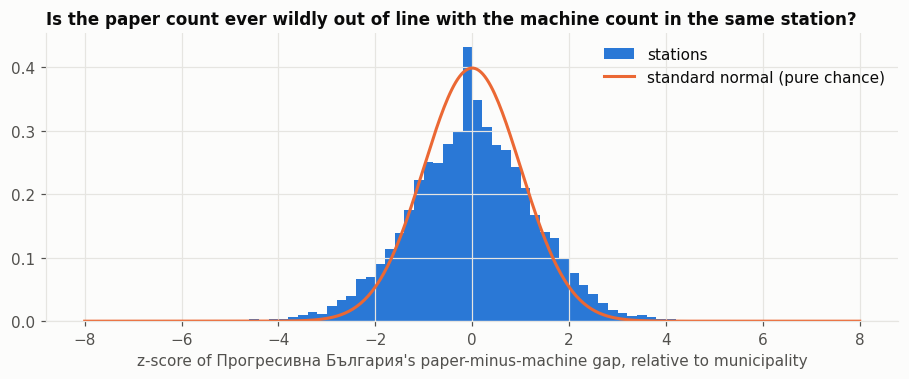

sd of z: 1.26 (1.0 = pure binomial chance);  |z| > 4: 28 stations (z > 4: 13, z < −4: 15);  normal expectation for |z| > 4: 0.5


,place,address,paper valid,machine valid,gap|21 Прогресивна България,z_gap
section,,,,,,
192700162,гр.Русе,"ГР.РУСЕ, ул. Студентска №10, СУЕЕ Св. Константин-Кирил Философ",120,118,+47%,+9.1
273700002,гр.Гурково,"ГР.ГУРКОВО, бул. Княз Ал. Батенберг №21, СУ Христо Смирненски",235,180,+10%,+5.9
182600029,с.Ясеновец,"С.ЯСЕНОВЕЦ, ДГ № 2 „Дора Габе“ - филиал, ул. „Дунав” № 35",65,245,+19%,+5.6
152400206,с.Буковлък,"С.БУКОВЛЪК, пл. Център №7, ОУ Св. Климент Охридски",349,102,-27%,-5.1
170100068,с.Боянци,"С.БОЯНЦИ, ОУ Проф. Д-р Асен Златаров, ул. Рила №2",137,91,+26%,+5.0
293400055,гр.Хасково,"ГР.ХАСКОВО, ОУ Шандор Петьофи , ж.к. Орфей 1",205,88,-40%,-4.9
263900004,гр.Самоков,"ГР.САМОКОВ, ОУ Христо Максимов , ул. Христо Максимов №1",112,124,-32%,-4.6
212000156,с.Младово,"С.МЛАДОВО, Ул. Столетов №2, Клуба до кметството",85,173,-32%,-4.5
121200004,гр.Вършец,"ГР.ВЪРШЕЦ, ул. Христо Ботев №44 (сградата на Сектор Чистота , Пенсионерски клуб)",197,181,-19%,-4.5


In [8]:
# Standardise the winner's gap against the binomial noise expected for that station, relative to the municipality's typical gap
c = WIN
p_pool = (vp.loc[M_.index, c] + vmach.loc[M_.index, c]) / (M_["paper valid"] + M_["machine valid"])
se = np.sqrt(p_pool * (1 - p_pool) * (1 / M_["paper valid"] + 1 / M_["machine valid"]))
M_["z_gap"] = (M_[f"gap|{c}"] - M_.groupby("municipality")[f"gap|{c}"].transform("median")) / se
z = M_["z_gap"].dropna()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(z.clip(-8, 8), bins=np.arange(-8, 8.01, 0.2), color=BLUE, linewidth=0, density=True, label="stations")
xx = np.linspace(-8, 8, 400); ax.plot(xx, stats.norm.pdf(xx), color=ORANGE, lw=2, label="standard normal (pure chance)")
ax.set_xlabel(f"z-score of {short(c)}'s paper-minus-machine gap, relative to municipality"); ax.legend()
ax.set_title("Is the paper count ever wildly out of line with the machine count in the same station?")
plt.show()
print(f"sd of z: {z.std():.2f} (1.0 = pure binomial chance);  |z| > 4: {(z.abs() > 4).sum()} stations "
      f"(z > 4: {(z > 4).sum()}, z < −4: {(z < -4).sum()});  normal expectation for |z| > 4: {2 * stats.norm.sf(4) * len(z):.1f}")
M_["flag_paper_gap"] = M_["z_gap"].abs() > 4
M_.loc[M_["flag_paper_gap"], ["place", "address", "paper valid", "machine valid", f"gap|{c}", "z_gap"]] \
    .sort_values("z_gap", key=abs, ascending=False).head(25).style.format({f"gap|{c}": "{:+.0%}", "z_gap": "{:+.1f}"})

## 2. Invalid ballots (paper stations only)
Declaring valid ballots invalid during the count is a classic way to take votes from a rival. Two checks:
1. **Outliers:** stations with far more invalid ballots than the rest of their municipality. We use a **beta-binomial** model
   because invalid rates vary more between stations than pure chance would predict. Multiple testing is controlled with Benjamini–Hochberg (q < 0.01).
2. **Who loses when invalid ballots are high?** Within the same municipality, regress each party's share on the station's invalid rate.

In [9]:
P = dom[dom["paper"] & dom["form"].isin([24, 28])].copy()        # pure paper protocols
P["box"] = P["valid"] + P["invalid"]
P["invalid rate"] = P["invalid"] / P["box"]
nat_rate = P["invalid"].sum() / P["box"].sum()
P["municipality rate"] = loo_rate(P["invalid"], P["box"], P["municipality"], nat_rate)
P["q"], rho_inv = betabinom_outliers(P["invalid"], P["box"], P["municipality rate"].clip(lower=0.003))
P["flag_invalid"] = P["q"] < 0.01
print(f"paper stations: {len(P):,};  invalid ballots: {P['invalid'].sum():,} ({nat_rate:.2%});  "
      f"stations with zero invalid: {(P['invalid'] == 0).mean():.0%}")
print(f"over-dispersion ρ = {rho_inv:.3f};  flagged stations (q < 0.01): {P['flag_invalid'].sum()}")
print(f"for comparison: invalid paper ballots in machine stations: {dom.loc[~dom['paper'], 'invalid'].sum():,} "
      f"({dom.loc[~dom['paper'], 'invalid'].sum() / pt.loc[dom.index[~dom['paper']], 'paper_in_box'].sum():.2%} of their paper ballots)")

paper stations: 2,547;  invalid ballots: 6,704 (3.23%);  stations with zero invalid: 24%
over-dispersion ρ = 0.014;  flagged stations (q < 0.01): 7
for comparison: invalid paper ballots in machine stations: 54,617 (3.83% of their paper ballots)


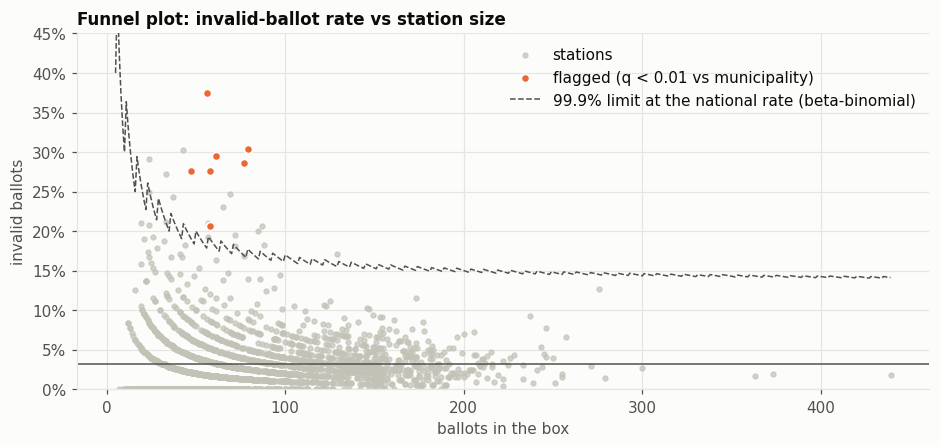

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ok = ~P["flag_invalid"]
ax.scatter(P.loc[ok, "box"], P.loc[ok, "invalid rate"], s=10, color=MUTED, alpha=0.7, label="stations", zorder=2)
ax.scatter(P.loc[~ok, "box"], P.loc[~ok, "invalid rate"], s=30, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=3,
           label="flagged (q < 0.01 vs municipality)")
nn = np.arange(5, P["box"].max() + 1)
a, b = nat_rate * (1 - rho_inv) / rho_inv, (1 - nat_rate) * (1 - rho_inv) / rho_inv
ax.plot(nn, stats.betabinom.ppf(0.999, nn, a, b) / nn, color=INK2, lw=1, ls="--", label="99.9% limit at the national rate (beta-binomial)")
ax.axhline(nat_rate, color=INK2, lw=1)
ax.set_xlabel("ballots in the box"); ax.set_ylabel("invalid ballots"); ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.45); ax.legend(loc="upper right")
ax.set_title("Funnel plot: invalid-ballot rate vs station size")
plt.show()

In [11]:
P["top party"] = P[[f"share|{c}" for c in cand_cols]].idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
P.loc[P["flag_invalid"], ["place", "address", "box", "invalid", "invalid rate", "municipality rate", "top party", "q"]] \
    .sort_values("q").style.format({"invalid rate": "{:.1%}", "municipality rate": "{:.1%}", "q": "{:.1e}"})

,place,address,box,invalid,invalid rate,municipality rate,top party,q
section,,,,,,,,
162206079,гр.Пловдив,"Дом за стари хора „Св. Василий“ - бул. „Цариградско шосе”, № 108",56,21,37.5%,5.9%,Прогресивна България,3.0e-03
265900007,гр.Долна баня,"ГР.ДОЛНА БАНЯ, ЦНСТ-1 Успение на Пресвета Богородица , местн. Циганско меше №1, ет.1",77,22,28.6%,3.2%,ГЕРБ–СДС,3.0e-03
290900079,с.Длъгнево,"С.ДЛЪГНЕВО, Пенсионерски клуб",79,24,30.4%,3.7%,Прогресивна България,3.0e-03
131900095,гр.Пазарджик,"ДСХ Г. Кръстевич , ул. Болнична №22",61,18,29.5%,3.3%,Прогресивна България,4.0e-03
090800024,с.Купците,"С.КУПЦИТЕ, сграда №10 - частен дом",58,12,20.7%,0.8%,ДПС,4.9e-03
223100087,с.Фатово,Дом за стари хора – с. Фатово,47,13,27.7%,2.3%,Прогресивна България,4.9e-03
061000115,гр.Враца,Затвор – гр. Враца,58,16,27.6%,3.2%,Прогресивна България,6.8e-03


In [12]:
rows = {}
for c in OUTCOMES:
    X = demean(P[["invalid rate"]], P["municipality"], P["box"])
    y = demean(P[f"share|{c}"], P["municipality"], P["box"])[:, 0]
    b, se = wls_cluster(y, X, P["box"], P["municipality"])
    rows[short(c)] = {"slope": b[0], "95% CI": f"{b[0] - 1.96*se[0]:+.2f} … {b[0] + 1.96*se[0]:+.2f}",
                      "share change if invalid rate +5 pts": b[0] * 0.05}
inv_slopes = pd.DataFrame(rows).T
inv_slopes.style.format({"slope": "{:+.2f}", "share change if invalid rate +5 pts": "{:+.1%}"})

,slope,95% CI,share change if invalid rate +5 pts
Прогресивна България,-0.17,-0.34 … +0.00,-0.8%
ГЕРБ–СДС,+0.00,-0.15 … +0.16,+0.0%
ПП–ДБ,-0.08,-0.17 … +0.01,-0.4%
ДПС,+0.03,-0.11 … +0.17,+0.2%
МЕЧ,+0.03,-0.00 … +0.07,+0.2%
Величие,-0.02,-0.06 … +0.01,-0.1%
Не подкрепям никого,+0.01,-0.01 … +0.03,+0.0%


**How to read the slopes.** If invalid ballots were a random slice of all ballots, every slope would be ~0. If they were taken
entirely from party X, X's slope would be close to −(1 − X's share). A negative slope can also be innocent: older voters spoil more
ballots and vote differently, even within one municipality.

**Here:** no meaningful slope. Прогресивна България −0.17 (CI −0.34 … 0.00) means −0.8 pts of share per +5 pts of invalid ballots, at the
edge of significance and of the size demography produces. МЕЧ and Величие have slopes of ±0.03. The 7 stations with far more invalid ballots
than their municipality are **care homes, a prison and a few small villages**, where confused or assisted voters naturally spoil more ballots.
Invalid paper ballots total ~61,300 nationwide (3.2% of paper ballots in paper stations, 3.8% in machine stations), and there is no sign they
were used against a particular party.

## 3. Voters added on election day (“под чертата”)
Voters not on the printed list can be added on the day. Adding fictitious voters is a known channel for fraud, and it is the channel
that matters for the **student double-voting** claim examined in `double_voting_parliament.ipynb`. Two checks:

**(a) How do added voters vote?** Each station's result mixes regular voters and added voters. Regressing a party's share on the
station's fraction of added voters (comparing stations in the same municipality) estimates **the share among added voters**.
Because the added fraction (added ÷ voted) is mechanically larger where turnout is low, we show the estimate with and without
controlling for turnout.

In [13]:
A = dom[(dom["registered"] >= 100) & (dom["voters_added"] / dom["registered"] <= 0.5)].copy()
A["added fraction"] = A["voters_added"] / A["voted"].clip(lower=1)
A = A[A["added fraction"] <= 1]
turnout_deciles = pd.get_dummies(pd.qcut(A["turnout"], 10), drop_first=True).astype(float)

def added_voter_share(data, cand, group, control_turnout):
    Xraw = data[["added fraction"]]
    if control_turnout:
        Xraw = pd.concat([Xraw, turnout_deciles.loc[data.index]], axis=1)
    keep = (data.groupby(group)["added fraction"].transform("size") >= 2).to_numpy()
    X = demean(Xraw, data[group], data["valid"])[keep]
    y = demean(data[f"share|{cand}"], data[group], data["valid"])[keep, 0]
    b, se = wls_cluster(y, X, data["valid"][keep], data[group][keep])
    base = data[cand].sum() / data["valid"].sum()
    return base, base + b[0], 1.96 * se[0]

specs = {"naive (same municipality)": ("municipality", False),
         "+ control for turnout": ("municipality", True),
         "+ turnout, same building": ("address", True)}
est = {}
for c in OUTCOMES:
    for name, (g, ctl) in specs.items():
        base, val, ci = added_voter_share(A, c, g, ctl)
        est[(short(c), name)] = (base, val, ci)
tab = pd.DataFrame({k: {"regular voters (overall)": v[0], "added voters (est.)": v[1], "± 95% CI": v[2]} for k, v in est.items()}).T
print(f"{len(A):,} stations, {A['voters_added'].sum():,} added voters ({A['voters_added'].sum() / A['voted'].sum():.1%} of all who voted)")
tab.style.format("{:.1%}")

10,801 stations, 85,941 added voters (2.8% of all who voted)


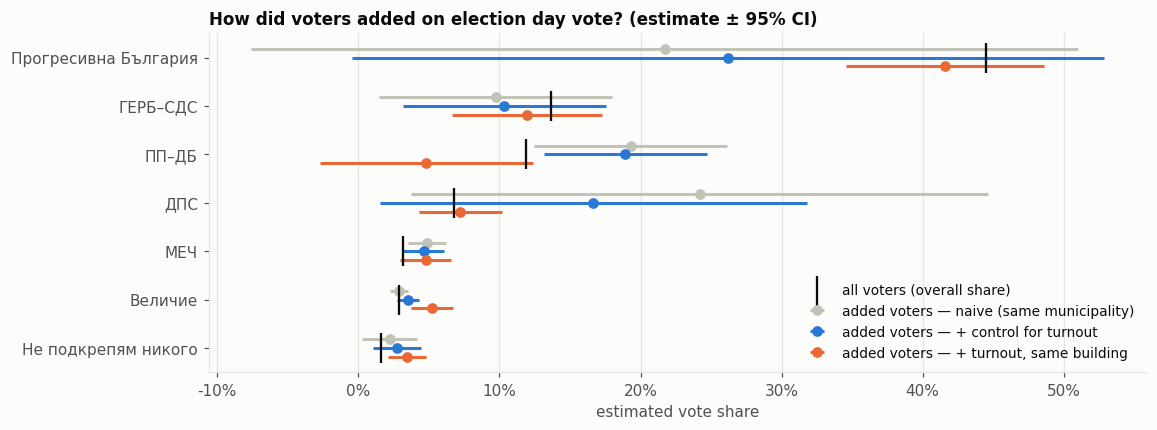

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
cands = [short(c) for c in OUTCOMES]
y0 = np.arange(len(cands))
offsets = {"naive (same municipality)": -0.18, "+ control for turnout": 0.0, "+ turnout, same building": 0.18}
colors = {"naive (same municipality)": MUTED, "+ control for turnout": BLUE, "+ turnout, same building": ORANGE}
for name, off in offsets.items():
    vals = [est[(c, name)] for c in cands]
    ax.errorbar([v[1] for v in vals], y0 + off, xerr=[v[2] for v in vals], fmt="o", ms=6, color=colors[name],
                ecolor=colors[name], elinewidth=2, capsize=0, label=f"added voters — {name}")
ax.scatter([est[(c, 'naive (same municipality)')][0] for c in cands], y0, marker="|", s=400, color=INK, zorder=4, label="all voters (overall share)")
ax.set_yticks(y0, cands); ax.invert_yaxis(); ax.xaxis.set_major_formatter(pct); ax.grid(axis="y", visible=False)
ax.set_xlabel("estimated vote share"); ax.legend(loc="lower right", fontsize=9)
ax.set_title("How did voters added on election day vote? (estimate ± 95% CI)")
plt.show()

**(b) Stations with unusually many added voters** relative to the rest of their municipality (added ÷ registered, beta-binomial,
q < 0.01). Some flagged stations will have innocent reasons: student dorms, resorts, hospitals, workplaces.

In [15]:
A["added rate"] = A["voters_added"] / A["registered"]
nat_added = A["voters_added"].sum() / A["registered"].sum()
A["municipality added rate"] = loo_rate(A["voters_added"], A["registered"], A["municipality"], nat_added)
A["q_added"], rho_add = betabinom_outliers(A["voters_added"], A["registered"], A["municipality added rate"].clip(lower=0.002))
A["flag_added"] = A["q_added"] < 0.01
A["top party"] = A[[f"share|{c}" for c in cand_cols]].idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
A["top share"] = A[[f"share|{c}" for c in cand_cols]].max(axis=1)
print(f"over-dispersion ρ = {rho_add:.3f};  flagged stations: {A['flag_added'].sum()}")
A.loc[A["flag_added"], ["place", "address", "registered", "voters_added", "voted", "added rate", "municipality added rate",
                         "top party", "top share", "q_added"]].sort_values("q_added").head(40).style.format(
    {"added rate": "{:.1%}", "municipality added rate": "{:.1%}", "top share": "{:.0%}", "q_added": "{:.1e}"})

over-dispersion ρ = 0.006;  flagged stations: 78


,place,address,registered,voters_added,voted,added rate,municipality added rate,top party,top share,q_added
section,,,,,,,,,,
234609081,гр.София,„АДЖИБАДЕМ СИТИ КЛИНИК УМБАЛ ТОКУДА“ ЕАД /бул. „Никола Вапцаров“ № 51-Б,860,307,363,35.7%,2.8%,Прогресивна България,36%,0.0e+00
234616006,гр.София,"ГР.СОФИЯ, ж.к. Студентски град , бл.54, вх.Б, ет.ІІ",1218,329,852,27.0%,2.8%,ПП–ДБ,46%,0.0e+00
234616005,гр.София,"ГР.СОФИЯ, ж.к. Студентски град , бл.13, ет.ІІ",1176,318,849,27.0%,2.8%,ПП–ДБ,42%,0.0e+00
234616002,гр.София,"ГР.СОФИЯ, ж.к. Студентски град , бл.26, ет.ІІ",1097,425,839,38.7%,2.7%,ПП–ДБ,42%,0.0e+00
234610113,гр.София,"ВОЕННОМЕДИЦИНСКА АКАДЕМИЯ, бул. „Св. Георги Софийски” № 3, учебна зала № 2, първи етаж /ет. I/ в основната сграда на ВМА",971,269,373,27.7%,2.8%,Прогресивна България,40%,0.0e+00
234610111,гр.София,"МБАЛ „СВ. ИВАН РИЛСКИ“ ЕАД, бул. Акад. Иван Гешов 15 - в учебна зала на първи етаж",113,50,68,44.2%,2.8%,Прогресивна България,42%,0.0e+00
234610109,гр.София,"СБАЛАГ „МАЙЧИН Дом” ЕАД, ул. „Здраве” № 2, кабинет 122, първи етаж /ет. I/- основна сграда",199,90,123,45.2%,2.8%,Прогресивна България,32%,0.0e+00
220200017,с.Баните,"с. Баните, ул.“Васил Левски“ № 2, Специализирана болница за рехабилитация-НК“ ЕАД, с. Баните",104,33,84,31.7%,1.0%,Прогресивна България,60%,0.0e+00
234616049,гр.София,"ГР.СОФИЯ, ж.к.Студентски град бл. 42, вх. Б, ет.ІІ",980,383,756,39.1%,2.7%,ПП–ДБ,43%,0.0e+00


In [16]:
flagged = A[A["flag_added"]]
comp = pd.DataFrame({
    "flagged stations": flagged[OUTCOMES].sum() / flagged["valid"].sum(),
    "all stations": A[OUTCOMES].sum() / A["valid"].sum(),
})
comp.index = [short(c) for c in comp.index]
print(f"Vote shares in the {len(flagged)} stations with unusually many added voters vs everywhere:")
comp.style.format("{:.1%}")

Vote shares in the 78 stations with unusually many added voters vs everywhere:


,flagged stations,all stations
Прогресивна България,37.4%,44.5%
ГЕРБ–СДС,9.5%,13.6%
ПП–ДБ,28.1%,11.9%
ДПС,1.2%,6.8%
МЕЧ,3.6%,3.2%
Величие,2.3%,2.9%
Не подкрепям никого,2.6%,1.6%


## 4. Do the protocols add up?
The CIK data-entry software rejects many inconsistent protocols, so most identities hold by construction. What slips through is
still informative. In this election every station has **one** protocol, with the paper part (items 3–9) and, where there was a
machine, the hand count of the machine receipts (items 11–14).

In [17]:
pp = pt.reindex(dom.index)
vp_sum = vp.drop(columns=NONE).sum(axis=1).reindex(dom.index)
vm_sum = vmach.drop(columns=NONE).sum(axis=1).reindex(dom.index)
checks = {
    "signatures ≠ paper ballots + machine receipts in the box": pp["voted_signatures"] != pp["paper_in_box"] + pp["machine_in_box"],
    "paper: ballots in box ≠ invalid + 'none' + valid": pp["paper_in_box"] != pp["invalid_paper"] + pp["none_paper"] + pp["valid_cand_paper"],
    "paper: received ≠ unused + destroyed + in box": pp["ballots_received"] != pp["unused_paper"] + pp["destroyed_paper"] + pp["paper_in_box"],
    "machine: receipts in box ≠ 'none' + valid": pp["machine_in_box"] != pp["none_machine"] + pp["valid_cand_machine"],
    "paper votes per party ≠ protocol item 9": vp_sum != pp["valid_cand_paper"],
    "machine votes per party ≠ protocol item 14": vm_sum != pp["valid_cand_machine"],
    "more voters than registered": dom["voted"] > dom["registered"],
    "more voters added on the day than voted (impossible; list size copied into 'added')": dom["voters_added"] > dom["voted"],
}
check_df = pd.DataFrame(checks)
dom["arith_issues"] = check_df.apply(lambda r: "; ".join(k for k, v in r.items() if v), axis=1)
dom["flag_arith"] = check_df.any(axis=1)
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="stations").to_frame()

,stations
signatures ≠ paper ballots + machine receipts in the box,87
paper: ballots in box ≠ invalid + 'none' + valid,1
paper: received ≠ unused + destroyed + in box,11
machine: receipts in box ≠ 'none' + valid,31
paper votes per party ≠ protocol item 9,1
machine votes per party ≠ protocol item 14,8
more voters than registered,0
more voters added on the day than voted (impossible; list size copied into 'added'),10


In [18]:
fl = dom["flag_arith"]
detail = dom.loc[fl, ["place", "form", "registered", "voted"]].copy()
detail["ballots + receipts in box"] = pp.loc[fl, "paper_in_box"] + pp.loc[fl, "machine_in_box"]
detail["valid votes (all parties)"] = dom.loc[fl, "valid"]
detail["signatures − ballots"] = detail["voted"] - detail["ballots + receipts in box"]
detail["issues"] = dom.loc[fl, "arith_issues"]
detail.sort_values("signatures − ballots", key=abs, ascending=False).head(40)

,place,form,registered,voted,ballots + receipts in box,valid votes (all parties),signatures − ballots,issues
section,,,,,,,,
060800018,с.Алтимир,26,334,109,204,196,-95,signatures ≠ paper ballots + machine receipts ...
261700005,гр.Елин Пелин,26,902,441,380,432,61,signatures ≠ paper ballots + machine receipts ...
030602142,гр.Варна,26,1011,543,526,526,17,signatures ≠ paper ballots + machine receipts ...
254619023,гр.София,26,910,449,433,423,16,signatures ≠ paper ballots + machine receipts ...
040600012,гр.Горна Оряховица,26,584,290,277,277,13,signatures ≠ paper ballots + machine receipts ...
244607062,гр.София,26,795,428,440,427,-12,signatures ≠ paper ballots + machine receipts ...
244614076,гр.София,26,735,333,323,310,10,signatures ≠ paper ballots + machine receipts ...
162201008,гр.Пловдив,26,738,408,398,407,10,signatures ≠ paper ballots + machine receipts ...
061000055,гр.Враца,26,651,321,331,329,-10,signatures ≠ paper ballots + machine receipts ...


**Reading it:** the protocols are almost fully consistent. 87 stations have a gap between signatures and ballots, almost all of 1–5 (a voter
who signed and left, or a receipt taken home). Two stand out:
* **Алтимир (060800018):** 109 signatures but 204 ballots. The 95 machine votes match the machine's own record exactly, so they are real. The
  committee entered only the *paper* voters as "signatures". Turnout is under-reported, not inflated.
* **Елин Пелин (261700005):** 441 signatures but only 380 ballots, and the paper-ballot account doesn't balance either (550 received, 519
  "unused", 179 in the box). Probably a miscount of the unused ballots. **One of the protocols most worth pulling.**

10 stations report **more voters added on the day than voted in total**, which is impossible. The list size was copied into the "added" field
(e.g. Варна 030604324: 815 on the list, 820 "added", 378 voted). This error inflates the "added voters" count by ~4,800 and matters for the
double-voting question (see `double_voting_parliament.ipynb`).

## 5. Machine records vs the hand count of machine receipts
Each voting machine prints a paper receipt that the voter drops into the ballot box. After closing, the committee **counts these
receipts by hand**, and *that hand count* is what goes into the protocol (items 11–14). The machine also stores its own **electronic
count**, signed with the machine's key and published as the `suemg` archives.

The two should agree. They can disagree innocently: a voter walks out with the receipt, or a receipt is torn or ruled invalid. These
innocent losses push the hand count **below** the machine count, and they hit every party **in proportion to its votes**.
Manipulation of the hand count looks different:
* receipts **moved** from one party to another: the hand count is *above* the machine count for the beneficiary;
* a **whole stack** for one party is lost or not recorded: a large gap for one party only.

In [19]:
mc = load_machine_counts(PARLIAMENT)
idx = mc.index.intersection(dom.index)
mc = mc.loc[idx]
hand = vmach.loc[idx, mc.columns]                      # protocol (hand count of receipts) per party, incl. 'none'
D = hand - mc                                          # + = hand count has more than the machine
mach_assigned = dom.index[dom["machines"] > 0]
used = pt.loc[mach_assigned, "machine_in_box"] > 0
print(f"stations with a machine assigned: {len(mach_assigned):,};  with machine votes in the protocol: {used.sum():,};  "
      f"with a published machine record: {len(idx):,}")
print(f"stations where the hand count differs from the machine for at least one party: {(D != 0).any(axis=1).sum():,} "
      f"({(D != 0).any(axis=1).mean():.0%})")
print(f"total machine votes: {mc.values.sum():,};  hand count: {hand.values.sum():,};  "
      f"net difference: {D.values.sum():+,};  sum of absolute differences: {np.abs(D.values).sum():,}")
kinds = pd.Series({
    "identical": (D == 0).all(axis=1).sum(),
    "hand count lower only (receipts missing)": ((D < 0).any(axis=1) & ~(D > 0).any(axis=1)).sum(),
    "hand count higher only": ((D > 0).any(axis=1) & ~(D < 0).any(axis=1)).sum(),
    "both higher and lower (votes moved between parties?)": ((D > 0).any(axis=1) & (D < 0).any(axis=1)).sum(),
}, name="stations")
kinds.to_frame()

stations with a machine assigned: 9,354;  with machine votes in the protocol: 9,111;  with a published machine record: 9,273
stations where the hand count differs from the machine for at least one party: 3,359 (36%)
total machine votes: 1,520,228;  hand count: 1,508,841;  net difference: -11,387;  sum of absolute differences: 13,837


,stations
identical,5914
hand count lower only (receipts missing),2720
hand count higher only,48
both higher and lower (votes moved between parties?),591


In [20]:
# Are the missing receipts spread in proportion to each party's machine votes (innocent), or concentrated?
loss, gain = (-D).clip(lower=0), D.clip(lower=0)
party_tab = pd.DataFrame({"machine votes": mc.sum(), "machine share": mc.sum() / mc.values.sum(),
                          "receipts missing": loss.sum(), "share of missing": loss.sum() / loss.values.sum(),
                          "receipts extra": gain.sum(), "share of extra": gain.sum() / gain.values.sum()})
party_tab["missing ÷ expected"] = party_tab["share of missing"] / party_tab["machine share"]
party_tab["extra ÷ expected"] = party_tab["share of extra"] / party_tab["machine share"]
party_tab.index = [short(c) for c in party_tab.index]
party_tab.sort_values("machine votes", ascending=False).head(12).style.format(
    {"machine votes": "{:,.0f}", "machine share": "{:.1%}", "receipts missing": "{:,.0f}", "share of missing": "{:.1%}",
     "receipts extra": "{:,.0f}", "share of extra": "{:.1%}", "missing ÷ expected": "{:.2f}", "extra ÷ expected": "{:.2f}"})

,machine votes,machine share,receipts missing,share of missing,receipts extra,share of extra,missing ÷ expected,extra ÷ expected
Прогресивна България,"702,135",46.2%,"5,354",42.5%,182,14.9%,0.92,0.32
ПП–ДБ,"293,175",19.3%,"2,474",19.6%,84,6.9%,1.02,0.36
ГЕРБ–СДС,"131,796",8.7%,"1,105",8.8%,50,4.1%,1.01,0.47
Възраждане,"68,468",4.5%,565,4.5%,24,2.0%,0.99,0.44
МЕЧ,"56,232",3.7%,524,4.2%,18,1.5%,1.12,0.40
Сияние,"56,208",3.7%,462,3.7%,64,5.2%,0.99,1.41
Величие,"40,497",2.7%,332,2.6%,14,1.1%,0.99,0.43
БСП–ОЛ,"38,976",2.6%,386,3.1%,32,2.6%,1.19,1.02
Не подкрепям никого,"28,014",1.8%,294,2.3%,510,41.6%,1.27,22.59
ДПС,"26,287",1.7%,251,2.0%,15,1.2%,1.15,0.71


"Expected" here means *proportional to the party's machine votes nationally*. Stations differ, so a better test compares, **station by
station**, each party's missing receipts with what that station's own machine shares predict. Under random loss of *k* receipts in a
station, each party's loss is roughly hypergeometric. A party that loses far more than that in one station lost a "stack". A party that
**gains** receipts can't be explained by loss at all.

In [21]:
tot_loss = loss.sum(axis=1)
exp_loss = mc.div(mc.sum(axis=1).clip(lower=1), axis=0).mul(tot_loss, axis=0)
# per station: is the loss concentrated on one party? (largest single-party loss and its share of the station's total loss)
big = loss.max(axis=1); big_party = loss.idxmax(axis=1)
conc = big / tot_loss.replace(0, np.nan)
p_hyper = pd.Series(np.nan, index=mc.index)
for s_ in tot_loss.index[tot_loss >= 5]:
    p_ = big_party[s_]
    p_hyper[s_] = stats.hypergeom.sf(big[s_] - 1, int(mc.loc[s_].sum()), int(mc.loc[s_, p_]), int(tot_loss[s_]))
q_stack = pd.Series(stats.false_discovery_control(p_hyper.dropna()), index=p_hyper.dropna().index)
stack = q_stack.index[(q_stack < 0.01) & (big.loc[q_stack.index] >= 10)]
STK = pd.DataFrame({"place": dom.loc[stack, "place"], "machine total": mc.loc[stack].sum(axis=1), "hand count total": hand.loc[stack].sum(axis=1),
                    "party losing": big_party[stack].map(short), "its machine votes": [mc.loc[s_, big_party[s_]] for s_ in stack],
                    "its hand count": [hand.loc[s_, big_party[s_]] for s_ in stack], "lost": big[stack],
                    "lost by all others": tot_loss[stack] - big[stack], "q": q_stack[stack]})
print(f"stations where one party lost a 'stack' of ≥ 10 receipts, far beyond random loss (q < 0.01): {len(STK)}")
print("by party:"); print(STK.groupby("party losing").agg(stations=("lost", "size"), receipts=("lost", "sum")).sort_values("receipts", ascending=False).to_string())
STK.sort_values("lost", ascending=False).style.format({"q": "{:.1e}"})

stations where one party lost a 'stack' of ≥ 10 receipts, far beyond random loss (q < 0.01): 6
by party:
                      stations  receipts
party losing                            
Прогресивна България         1       101
ПП–ДБ                        2       100
ГЕРБ–СДС                     2        26
Сияние                       1        10


,place,machine total,hand count total,party losing,its machine votes,its hand count,lost,lost by all others,q
section,,,,,,,,,
192700162,гр.Русе,220,118,Прогресивна България,101,0,101,1,1.8e-60
234608012,гр.София,271,181,ПП–ДБ,100,10,90,0,2.0e-58
040600002,гр.Горна Оряховица,261,261,ГЕРБ–СДС,16,0,16,2,2.9e-21
162201055,гр.Пловдив,422,408,Сияние,20,10,10,4,3.0e-10
170100050,гр.Асеновград,116,106,ПП–ДБ,19,9,10,0,6.3e-08
244607022,гр.София,160,150,ГЕРБ–СДС,13,3,10,0,1.4e-11


In [22]:
# Gains: hand count above the machine count for a party. Which parties gain, compared with their share of votes in those stations?
G = gain[(gain.sum(axis=1) > 0)]
exp_gain = mc.loc[G.index].div(mc.loc[G.index].sum(axis=1), axis=0).mul(G.sum(axis=1), axis=0)
gt = pd.DataFrame({"stations with a gain": (G > 0).sum(), "receipts gained": G.sum(), "expected if proportional": exp_gain.sum()})
gt["gained ÷ expected"] = gt["receipts gained"] / gt["expected if proportional"]
gt.index = [short(c) for c in gt.index]
print(f"{len(G)} stations where at least one party has more votes in the hand count than in the machine record; "
      f"{int(G.values.sum()):,} receipts in total")
gt[gt["receipts gained"] > 0].sort_values("receipts gained", ascending=False).head(12).style.format(
    {"receipts gained": "{:.0f}", "expected if proportional": "{:.1f}", "gained ÷ expected": "{:.2f}"})

639 stations where at least one party has more votes in the hand count than in the machine record; 1,225 receipts in total


,stations with a gain,receipts gained,expected if proportional,gained ÷ expected
Не подкрепям никого,276,510,22.6,22.62
Прогресивна България,141,182,577.5,0.32
ПП–ДБ,54,84,218.0,0.39
Сияние,19,64,39.6,1.61
ГЕРБ–СДС,33,50,107.2,0.47
АПС,18,39,7.8,4.99
Глас народен,6,36,1.8,19.62
БСП–ОЛ,18,32,33.3,0.96
Пряка демокрация,13,27,3.8,7.08
Непокорна България,11,27,2.5,10.81


In [23]:
# Stations with the largest gains for any single party (≥ 10 receipts)
gmax = gain.max(axis=1); gparty = gain.idxmax(axis=1)
GG = gmax[gmax >= 10].index
pd.DataFrame({"place": dom.loc[GG, "place"], "party gaining": gparty[GG].map(short), "machine": [mc.loc[s_, gparty[s_]] for s_ in GG],
              "hand count": [hand.loc[s_, gparty[s_]] for s_ in GG], "gain": gmax[GG],
              "other parties' net change": D.loc[GG].sum(axis=1) - gmax[GG]}).sort_values("gain", ascending=False)

,place,party gaining,machine,hand count,gain,other parties' net change
section,,,,,,
234609043,гр.София,Глас народен,0,24,24,0
254619013,гр.София,Сияние,12,29,17,-18
040600002,гр.Горна Оряховица,Непокорна България,1,14,13,-13
234602033,гр.София,Сияние,8,20,12,0
013300062,с.Първомай,Не подкрепям никого,2,12,10,-10
020400233,гр.Бургас,АПС,1,11,10,0
091500003,гр.Крумовград,БСП–ОЛ,0,10,10,-10
312500047,с.Ханово,ГЕРБ–СДС,5,15,10,-37


In [24]:
# Where are receipts missing? Share of machine votes not found in the box, by region
mr = pd.DataFrame({"machine": mc.sum(axis=1), "missing": tot_loss, "region": dom.loc[idx, "admin_name"]})
reg_tab = mr.groupby("region").agg(stations=("machine", "size"), machine_votes=("machine", "sum"), missing=("missing", "sum"))
reg_tab["missing %"] = reg_tab["missing"] / reg_tab["machine_votes"]
reg_tab["stations with any missing"] = mr.groupby("region")["missing"].apply(lambda s: (s > 0).mean())
reg_tab.sort_values("missing %", ascending=False).head(10).style.format({"missing %": "{:.2%}", "stations with any missing": "{:.0%}"})

,stations,machine_votes,missing,missing %,stations with any missing
region,,,,,
09. КЪРДЖАЛИ,346,12759,275,2.16%,23%
31. ЯМБОЛ,150,18874,289,1.53%,49%
24. СОФИЯ 24 МИР,487,125533,1842,1.47%,61%
27. СТАРА ЗАГОРА,358,66321,910,1.37%,51%
07. ГАБРОВО,155,22942,287,1.25%,59%
28. ТЪРГОВИЩЕ,165,12655,155,1.22%,29%
13. ПАЗАРДЖИК,314,44226,516,1.17%,40%
04. ВЕЛИКО ТЪРНОВО,302,44981,461,1.02%,41%
29. ХАСКОВО,344,38705,376,0.97%,32%


In [25]:
# Machines that were assigned but not used: the whole station voted on paper (counted by the committee)
nm = dom.loc[mach_assigned[~used.to_numpy()]]
print(f"{len(nm)} stations had a machine assigned but recorded no machine votes (machine failure or not used)")
cmpm = pd.DataFrame({"stations without a working machine": nm[OUTCOMES].sum() / nm["valid"].sum(),
                     "same municipalities, machine stations": dom[dom["municipality"].isin(nm["municipality"]) & ~dom["paper"]
                                                                  & ~dom.index.isin(nm.index)].pipe(lambda t: t[OUTCOMES].sum() / t["valid"].sum())})
cmpm.index = [short(c) for c in cmpm.index]
print(nm["admin_name"].value_counts().head(8).to_string())
cmpm.style.format("{:.1%}")

243 stations had a machine assigned but recorded no machine votes (machine failure or not used)
admin_name
09. КЪРДЖАЛИ          133
29. ХАСКОВО            19
30. ШУМЕН              12
28. ТЪРГОВИЩЕ          12
18. РАЗГРАД            11
08. ДОБРИЧ             10
02. БУРГАС              7
04. ВЕЛИКО ТЪРНОВО      5


,stations without a working machine,"same municipalities, machine stations"
Прогресивна България,23.6%,41.0%
ГЕРБ–СДС,6.9%,12.9%
ПП–ДБ,4.3%,16.6%
ДПС,50.4%,5.3%
МЕЧ,1.4%,3.0%
Величие,1.2%,2.8%
Не подкрепям никого,0.9%,1.8%


**Reading it:** this is the most direct audit in the whole analysis, and the overall picture is reassuring, with a handful of sharp exceptions.

* **The hand count is lower than the machine in 36% of machine stations, by 11,387 votes in total (0.75%).** The missing receipts are spread
  across parties **in proportion to their votes**: Прогресивна България 0.92× expected, ПП–ДБ 1.02, ГЕРБ 1.01, МЕЧ 1.12, Величие 0.99. That is
  what voters walking out with their receipts, or receipts torn or ruled invalid, look like. Nobody's receipts were systematically removed.
* **Six stations lost a whole "stack" for one party**, far beyond random loss. The biggest two hurt the winner and the opposition:
  - **Русе 192700162**: the machine recorded **101 votes for Прогресивна България; the protocol gives it 0** from machines (it only got its 56
    paper votes). Every other party's machine count matches within 1. The same station tops the paper-vs-machine gap list.
  - **Sofia 234608012**: the machine recorded **100 ПП–ДБ votes; the protocol says 10**. Almost certainly a dropped digit.
* **Gains** (hand count above the machine) are rare: 1,225 receipts in 639 stations, mostly 1–2 per station. The biggest "gainer" is **"Не
  подкрепям никого" (510, 23× its share)**, which suggests committees file doubtful receipts as "none" rather than as invalid. Прогресивна
  България gains *less* than its share (0.32×). A few small parties gain 10–24 votes in single stations (Глас народен +24 in Sofia 234609043,
  where the machine shows 0; Сияние +17, Непокорна България +13). These are worth checking, but they involve tens of votes.
* **243 stations had a machine but recorded no machine votes**, so the whole station voted on paper. **133 of them are in Кърджали**, where
  these stations gave **ДПС 50%** against 5% in machine stations of the same municipalities. This is the paper-voting enclave where count
  manipulation is easiest. It is the clearest structural irregularity in the election, and it concerns ДПС, not the winner.

## 6. Combined watch-list
One flag alone is usually innocent. **Several independent flags in the same station** are much more interesting.

| flag | meaning |
|---|---|
| `invalid` | far more invalid ballots than the municipality (q < 0.01) |
| `added` | far more voters added on the day than the municipality (q < 0.01) |
| `arith` | protocol doesn't add up |
| `list_error` | ~100% turnout with a voter list much smaller than the same-building neighbours |
| `extreme` | turnout > 70% and one party > 70% |
| `low_t_bloc` | turnout < 40% of the municipality median and one party > 50% |
| `paper_gap` | the winner's paper share differs from its machine share in the same station by > 4 standard errors |
| `receipt_stack` | one party lost ≥ 10 machine receipts, far beyond random loss |
| `receipt_gain` | the hand count gives a party ≥ 5 more votes than the machine recorded |
| `parl_surge` | parliamentary turnout > 2.5× what the station's presidential turnout and its municipality predict |

In [26]:
w = dom.copy()
w["flag_invalid"] = P["flag_invalid"].reindex(w.index, fill_value=False)
w["flag_added"] = A["flag_added"].reindex(w.index, fill_value=False)
bld_n = w.groupby("address")["voters_list"].transform("size")
bld_list = w.groupby("address")["voters_list"].transform(lambda s: s.sum() - s) / (bld_n - 1).replace(0, np.nan)
w["flag_list_error"] = (w["turnout"] >= 0.95) & (w["voters_list"] < 0.6 * bld_list)
shares = w[[f"share|{c}" for c in cand_cols]]
w["top party"] = shares.idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
w["top share"] = shares.max(axis=1)
regular = (w["registered"] >= 100) & (w["voters_added"] / w["registered"] <= 0.5)
w["flag_extreme"] = regular & (w["turnout"] > 0.7) & (w["top share"] > 0.7)
muni_t = w[regular].groupby("municipality")["turnout"].median()
w["flag_low_t_bloc"] = regular & (w["turnout"] < 0.4 * w["municipality"].map(muni_t)) & (w["top share"] > 0.5)
w["flag_paper_gap"] = M_["flag_paper_gap"].reindex(w.index, fill_value=False)
w["flag_receipt_stack"] = w.index.isin(stack)
w["flag_receipt_gain"] = w.index.isin(gmax.index[gmax >= 5])
# parliament-only surge (see turnout notebook, section 11)
r1m = load_sections(ROUND1)
r1t = r1m["voted_signatures"] / (r1m["voters_list"] + r1m["voters_added"])
cm = w.index.intersection(r1m.index)
Rr = pd.DataFrame({"t": w.loc[cm, "turnout"], "tp": r1t.loc[cm], "m": w.loc[cm, "municipality"], "reg": w.loc[cm, "registered"],
                   "regp": (r1m["voters_list"] + r1m["voters_added"]).loc[cm], "voted": w.loc[cm, "voted"]})
Rr = Rr[(Rr["regp"] >= 100) & ((Rr["reg"] / Rr["regp"] - 1).abs() < 0.3) & regular.loc[Rr.index]]
Rr["ratio"] = Rr["t"] / Rr["tp"].clip(lower=0.01)
Rr["rel"] = Rr["ratio"] / np.exp(np.log(Rr["ratio"]).groupby(Rr["m"]).transform("median"))
w["flag_parl_surge"] = w.index.isin(Rr.index[(Rr["rel"] > 2.5) & (Rr["voted"] >= 100)])

FLAGS = ["flag_invalid", "flag_added", "flag_arith", "flag_list_error", "flag_extreme", "flag_low_t_bloc",
         "flag_paper_gap", "flag_receipt_stack", "flag_receipt_gain", "flag_parl_surge"]
w["n_flags"] = w[FLAGS].sum(axis=1)
w["flags"] = w[FLAGS].apply(lambda r: ", ".join(k.replace("flag_", "") for k, v in r.items() if v), axis=1)
summary = pd.Series({k.replace("flag_", ""): int(w[k].sum()) for k in FLAGS} | {"≥ 2 flags": int((w["n_flags"] >= 2).sum()),
                                                                                 "≥ 3 flags": int((w["n_flags"] >= 3).sum())}, name="stations")
summary.to_frame()

,stations
invalid,7
added,78
arith,129
list_error,13
extreme,27
low_t_bloc,108
paper_gap,28
receipt_stack,6
receipt_gain,37
parl_surge,204


In [27]:
watch = w[w["n_flags"] >= 1].sort_values(["n_flags", "top share"], ascending=False)
cols = ["n_flags", "flags", "place", "address", "registered", "voters_added", "voted", "turnout", "invalid", "top party", "top share"]
watch[cols].to_csv("watchlist_parliament.csv")
print(f"{len(watch)} flagged stations saved to watchlist_parliament.csv")
watch.loc[watch["n_flags"] >= 2, cols].style.format({"turnout": "{:.0%}", "top share": "{:.0%}"})

597 flagged stations saved to watchlist_parliament.csv


,n_flags,flags,place,address,registered,voters_added,voted,turnout,invalid,top party,top share
section,,,,,,,,,,,
170100090,3,"list_error, extreme, paper_gap",с.Боянци,"С.БОЯНЦИ, ОУ Проф. Д-р Асен Златаров, ул. Рила №2",207,5,207,100%,16,Прогресивна България,77%
192700162,3,"arith, paper_gap, receipt_stack",гр.Русе,"ГР.РУСЕ, ул. Студентска №10, СУЕЕ Св. Константин-Кирил Философ",669,6,336,50%,0,ПП–ДБ,24%
010200011,2,"extreme, parl_surge",с.Бабяк,"С.БАБЯК, УЧИЛИЩЕ",572,7,466,81%,7,ДПС,96%
015300012,2,"extreme, parl_surge",с.Бунцево,"С.БУНЦЕВО, КМЕТСТВО",340,5,281,83%,6,ДПС,88%
010200010,2,"extreme, parl_surge",с.Лютово,"С.ЛЮТОВО, КМЕТСТВО",163,7,132,81%,4,ДПС,88%
015300011,2,"extreme, parl_surge",с.Конарско,"С.КОНАРСКО, КМЕТСТВО",715,4,506,71%,8,ДПС,72%
020400260,2,"low_t_bloc, parl_surge",гр.Бургас,"ГР.БУРГАС, кв.Рудник ОУ Св. Климент Охридски",728,5,117,16%,15,Прогресивна България,68%
212000116,2,"low_t_bloc, parl_surge",гр.Сливен,"ГР.СЛИВЕН, ул. Гоце Делчев №1, ОУ Братя Миладинови",1126,10,150,13%,6,Прогресивна България,67%
254611059,2,"low_t_bloc, parl_surge",гр.София,"ГР.СОФИЯ, 75 ОУ, кв. Факултета, бул. Възкресение №151",1098,7,196,18%,14,Прогресивна България,65%


In [28]:
# Which party leads in flagged stations, compared with how often each party leads overall?
lead_all = w.loc[regular, "top party"].value_counts(normalize=True)
lead_flag = pd.DataFrame({k.replace("flag_", ""): w.loc[w[k], "top party"].value_counts() for k in FLAGS}).fillna(0).astype(int)
lead_flag["share of all stations they lead"] = lead_all.reindex(lead_flag.index)
lead_flag.sort_values("share of all stations they lead", ascending=False).head(8).style.format({"share of all stations they lead": "{:.0%}"})

,invalid,added,arith,list_error,extreme,low_t_bloc,paper_gap,receipt_stack,receipt_gain,parl_surge,share of all stations they lead
top party,,,,,,,,,,,
Прогресивна България,5,64,113,13,6,94,22,5,34,87,82%
ДПС,1,0,12,0,17,10,2,0,0,84,10%
ПП–ДБ,0,13,2,0,0,1,2,1,3,2,5%
ГЕРБ–СДС,1,1,2,0,4,3,0,0,0,21,3%
АПС,0,0,0,0,0,0,2,0,0,7,1%
БСП–ОЛ,0,0,0,0,0,0,0,0,0,3,0%


## 7. Scale: how many votes would change the majority?
Every anomaly above needs a yardstick. Seats are allocated nationally among parties with at least **4% of the valid votes**
(including "Не подкрепям никого"), by the **largest-remainder (Hare–Niemeyer)** method. The allocation to the 31 multi-member constituencies doesn't
change national party totals, so a national calculation is enough to see whether a majority holds. (The final CIK allocation may
differ by a seat because of how remainders are handled across constituencies.)

Прогресивна България needs **121 of 240** seats for an absolute majority.

In [29]:
def hare_niemeyer(v, seats=240, threshold=0.04, base=None):
    base = v.sum() if base is None else base
    ok = v[v >= threshold * base]
    q = ok / ok.sum() * seats
    s = np.floor(q).astype(int)
    rem = seats - s.sum()
    s[(q - s).sort_values(ascending=False).index[:rem]] += 1
    return s.sort_values(ascending=False)

party_tot = votes[cand_cols].sum()
valid_all = votes.sum().sum()                       # threshold base includes 'none of the above'
seats = hare_niemeyer(party_tot, base=valid_all)
seat_tab = pd.DataFrame({"votes": party_tot[seats.index], "share of valid votes": party_tot[seats.index] / valid_all, "seats": seats})
seat_tab.index = [short(c) for c in seat_tab.index]
print(f"threshold: {0.04 * valid_all:,.0f} votes")
seat_tab.style.format({"votes": "{:,.0f}", "share of valid votes": "{:.2%}"})

threshold: 131,636 votes


,votes,share of valid votes,seats
Прогресивна България,"1,444,920",43.91%,131
ГЕРБ–СДС,"433,755",13.18%,39
ПП–ДБ,"408,846",12.42%,37
ДПС,"230,693",7.01%,21
Възраждане,"137,940",4.19%,12


In [30]:
def winner_seats(remove_from_winner=0, add_to=None, add=0):
    v = party_tot.copy().astype(float)
    v[WIN] -= remove_from_winner
    if add_to is not None: v[add_to] += add
    base = valid_all - remove_from_winner + add
    return hare_niemeyer(v, base=base).get(WIN, 0)

# (a) how many of the winner's votes would have to be illegitimate (removed) to lose the majority?
lo, hi = 0, int(party_tot[WIN])
while lo < hi:
    mid = (lo + hi) // 2
    if winner_seats(remove_from_winner=mid) <= 120: hi = mid
    else: lo = mid + 1
remove_needed = lo
# (b) parties just below the threshold: how many votes short, and what would happen to the majority if they had crossed it?
below = party_tot[(party_tot < 0.04 * valid_all)].sort_values(ascending=False).head(3)
rows = {}
for c in below.index:
    need = int(np.ceil((0.04 * valid_all - party_tot[c]) / 0.96)) + 1
    rows[short(c)] = {"votes": party_tot[c], "votes short of 4%": need, f"{short(WIN)} seats if it had crossed": winner_seats(add_to=c, add=need)}
def lift_over_threshold(parties):
    # add the fewest votes so that all `parties` are at or above 4% at the same time (the threshold rises as votes are added)
    v = party_tot.copy().astype(float); extra = 0
    while True:
        short_by = {c: 0.04 * (valid_all + extra) - v[c] for c in parties}
        if all(x <= 0 for x in short_by.values()): return v, extra
        for c, x in short_by.items():
            if x > 0:
                add = int(np.ceil(x / 0.96)) + 1; v[c] += add; extra += add

both = below.index[:2]
v2, extra = lift_over_threshold(both)
both_seats = hare_niemeyer(v2, base=valid_all + extra).get(WIN, 0)
v3, extra3 = lift_over_threshold(below.index[:3])
three_seats = hare_niemeyer(v3, base=valid_all + extra3).get(WIN, 0)
print(f"{short(WIN)}: {seats[WIN]} seats (majority = 121).")
print(f"(a) votes that would have to be removed from {short(WIN)} alone to lose the majority: {remove_needed:,}")
print(f"(b) if both {short(both[0])} and {short(both[1])} had crossed 4% ({extra:,} extra votes in total): {short(WIN)} would have {both_seats} seats")
print(f"(c) if all three of {', '.join(short(c) for c in below.index[:3])} had crossed 4% ({extra3:,} extra votes): {short(WIN)} would have {three_seats} seats")
pd.DataFrame(rows).T.style.format("{:,.0f}")

Прогресивна България: 131 seats (majority = 121).
(a) votes that would have to be removed from Прогресивна България alone to lose the majority: 221,555
(b) if both МЕЧ and Величие had crossed 4% (63,256 extra votes in total): Прогресивна България would have 119 seats
(c) if all three of МЕЧ, Величие, БСП–ОЛ had crossed 4% (104,632 extra votes): Прогресивна България would have 113 seats


,votes,votes short of 4%,Прогресивна България seats if it had crossed
МЕЧ,"104,506","28,261",124
Величие,"100,572","32,359",124
БСП–ОЛ,"97,753","35,296",124


## 8. Conclusions

| Check | Finding | Fraud signal? |
|---|---|---|
| **Paper vs machine (RDD at 300 voters)** | No jump for any party (incl. МЕЧ, Величие) or turnout. But just above 300, three quarters of voters still chose paper, so the test is weak (the invalid-ballot control doesn't move). | **No**, with low power |
| **Paper vs machine inside each station** | The winner's paper and machine shares differ by 1.8 pts nationally (paper voters are older). 28 stations are beyond 4 SE, split evenly (13 above, 15 below). | **No systematic direction** |
| **Invalid-ballot outliers** | 7 stations, all care homes, a prison or tiny villages. No party loses meaningfully where invalid rates are high. | **No** |
| **How added voters vote** | Within the same building, added voters vote like everyone else (winner 41.6% ± 7.0 vs 44.5%). | **No** |
| **Stations with many added voters** | 78 stations: hospitals, sanatoria, prisons, the Military Medical Academy and **Sofia's Студентски град** (where ПП–ДБ leads). | **No** (see `double_voting_parliament.ipynb`) |
| **Protocol arithmetic** | Almost fully consistent; 2 protocols with large gaps (Алтимир, Елин Пелин); 10 with the "added > voted" copy error. | **No** (data quality) |
| **Machine record vs hand count** | 11,387 receipts missing (0.75%), spread **in proportion** to every party's votes. 6 single-party "stacks" lost; the largest cost **Прогресивна България 101** (Русе) and **ПП–ДБ 90** (Sofia). Gains are rare and go mostly to "none". | **No manipulation in favour of the winner.** A few protocols to correct. |
| **Machines not used** | 243 stations, **133 in Кърджали**, where they voted 50% ДПС on paper. | **Structural irregularity**, ДПС-related |
| **Combined watch-list** | 597 flagged stations, 38 with two or more flags, 2 with three: Боянци (list error + extreme + paper gap; 77% for the winner, 100% "turnout") and Русе 192700162 (the lost 101 votes). | **No multi-flag hotspots** |

### How much would it take?
Прогресивна България holds **131 of 240 seats**. Removing **~221,500** of its votes would cost the majority. But the majority is also
exposed from below: if **МЕЧ and Величие had both reached 4%** (~63,000 more votes between them), the winner would have only **119 seats**.
So the decisive question for any fraud allegation is whether ~30,000 votes each were taken from those two parties. Nothing above
points that way. They lose machine receipts in proportion to their votes, don't jump at the paper/machine threshold, and don't lose share
where invalid ballots are high.

### Bottom line
**The counting stage shows no manipulation in favour of the winner.** Machine records, the strongest evidence available, agree with the hand
count to within 0.75%, and the differences hit every party proportionally. The biggest single discrepancies *cost* the winner and the main
opposition votes. What stands out is (1) the paper-only voting in 133 Кърджали stations with unused machines, (2) a few dozen protocols
with clear recording errors, and (3) the localised organised-voting patterns from the turnout notebook.

### Across all four notebooks
| Notebook | Looks for | Result |
|---|---|---|
| `benford_parliament.ipynb` | invented numbers | nothing beyond what honest counts produce |
| `turnout_fingerprint_parliament.ipynb` | ballot stuffing, controlled voting | no stuffing for the winner; "parliament-only" mobilisation strongly favours ДПС (and ГЕРБ); small low-turnout bloc pattern for the winner (32 stations) |
| `ballot_anomalies_parliament.ipynb` | count manipulation, voter-list abuse | machine records match the hand count; a few protocol errors; Кърджали paper-only enclave |
| `double_voting_parliament.ipynb` | students voting twice | no surplus of added voters; the channel is far too small to matter |

`watchlist_parliament.csv` lists every flagged station with its reasons, for checking against the scanned protocols on the CIK website.